# 第 10 章配套 Notebook：近似误差会不会让选邻居出错：2ε 距离界、4ε 不变定理与时间步 T 翻转实验

[![Open In Colab (main)](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Casey-sketch-cyber/gnn2gsnn/blob/main/notion/notebooks/ch10_knn_stability.ipynb) （PR 审查期分支链接：[点此在 Colab 打开 gemini/deep-03 版](https://colab.research.google.com/github/Casey-sketch-cyber/gnn2gsnn/blob/gemini/deep-03/notion/notebooks/ch10_knn_stability.ipynb)）

> **运行环境**：仅需 Python ≥ 3.10、`numpy`、`matplotlib`，不需要 GPU，也不依赖 PyTorch 等深度学习框架。所有公式推导、手算例与反例均直接打印中间结果并与第 10 章正文逐位核对一致。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

# 配置中文与负号显示（Windows / Linux / macOS / Colab 通用回退）
matplotlib.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'Arial Unicode MS', 'DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False
np.set_printoptions(precision=6, suppress=True)
print("NumPy version:", np.__version__)


NumPy version: 2.5.5


## 1. 三角不等式与 $2\varepsilon$ 成对距离扰动界验证

若每个节点的脉冲近似特征都满足 $\lVert \hat{\mathbf{x}}_u - \mathbf{x}_u \rVert_2 \le \varepsilon$，则任意两点间欧氏距离的变化满足：
$$\Big\lvert \lVert \hat{\mathbf{x}}_i - \hat{\mathbf{x}}_j \rVert_2 - \lVert \mathbf{x}_i - \mathbf{x}_j \rVert_2 \Big\rvert \le 2\varepsilon$$
用 10,000 次随机扰动和 1 次共线反向最坏扰动验证：上界 $2\varepsilon$ 永远成立且可严格取等！

In [2]:
rng = np.random.default_rng(10)
eps = 0.15
C = 8
x_i = rng.normal(size=C)
x_j = rng.normal(size=C)
d_true = float(np.linalg.norm(x_i - x_j))

# 10,000 次球内随机扰动
dirs_i = rng.normal(size=(10_000, C))
dirs_i /= np.linalg.norm(dirs_i, axis=1, keepdims=True)
radii_i = eps * (rng.random((10_000, 1)) ** (1.0 / C))
x_i_hat = x_i + dirs_i * radii_i

dirs_j = rng.normal(size=(10_000, C))
dirs_j /= np.linalg.norm(dirs_j, axis=1, keepdims=True)
radii_j = eps * (rng.random((10_000, 1)) ** (1.0 / C))
x_j_hat = x_j + dirs_j * radii_j

d_hat = np.linalg.norm(x_i_hat - x_j_hat, axis=1)
max_rand_diff = float(np.max(np.abs(d_hat - d_true)))

# 最坏共线反向扰动（严格取等 2*eps）
u_dir = (x_i - x_j) / d_true
x_i_worst = x_i + eps * u_dir
x_j_worst = x_j - eps * u_dir
d_worst = float(np.linalg.norm(x_i_worst - x_j_worst))

print(f"真实距离 d_ij = {d_true:.6f}, eps = {eps:.2f}, 理论最大扰动 2*eps = {2*eps:.6f}")
print(f"10,000 次随机球内扰动最大 |d_hat - d| = {max_rand_diff:.6f} <= {2*eps:.6f}")
print(f"最坏共线反向扰动 |d_worst - d|         = {abs(d_worst - d_true):.6f} (精确取等 2*eps！)")
assert max_rand_diff <= 2 * eps + 1e-12
assert np.isclose(abs(d_worst - d_true), 2 * eps)


真实距离 d_ij = 3.323218, eps = 0.15, 理论最大扰动 2*eps = 0.300000
10,000 次随机球内扰动最大 |d_hat - d| = 0.220213 <= 0.300000
最坏共线反向扰动 |d_worst - d|         = 0.300000 (精确取等 2*eps！)


## 2. $4\varepsilon$ 邻居不变定理手算例（例 10.1：稳定区 vs 翻转区，顺便证明 $4\varepsilon$ 是紧界！）

构造 4 节点二维图（$k=2$，查询节点 0 在原点 $\mathbf{x}_0 = [0, 0]^\top$）：
- $\mathbf{x}_1 = [1.0, 0.0]^\top$（$d_{01}=1.0$，第 1 近邻）；
- $\mathbf{x}_2 = [0.0, 2.0]^\top$（$d_{02}=2.0$，第 $k=2$ 近邻）；
- $\mathbf{x}_3 = [0.0, -2.5]^\top$（$d_{03}=2.5$，第 $k+1=3$ 近邻）。

第 2 近与第 3 近的距离间隔 $\Delta d_2(0) = d_{(3)}(0) - d_{(2)}(0) = 2.5 - 2.0 = \mathbf{0.50}$，临界半径 $\varepsilon_{\mathrm{crit}} = \frac{0.50}{4} = \mathbf{0.125}$。
- **情形 A（$\varepsilon = 0.10 < 0.125$，$\Delta d_2 > 4\varepsilon = 0.40$）**：即便施加最坏对抗扰动，$\hat{d}_{02}=2.20 < \hat{d}_{03}=2.30$，top-2 邻居集合严格保持 `{1, 2}`！
- **情形 B（$\varepsilon = 0.15 > 0.125$，$\Delta d_2 < 4\varepsilon = 0.60$）**：在同样的最坏扰动下，$\hat{d}_{02}=2.30 > \hat{d}_{03}=2.20$，**发生邻居翻转**，top-2 集合变成 `{1, 3}`！

In [3]:
X_nodes = np.array([
    [0.0,  0.0],  # 节点 0 (查询节点)
    [1.0,  0.0],  # 节点 1: d = 1.0 (第 1 近)
    [0.0,  2.0],  # 节点 2: d = 2.0 (第 2 近)
    [0.0, -2.5],  # 节点 3: d = 2.5 (第 3 近)
])

def knn_of_node0(X, k=2):
    dists = np.linalg.norm(X[1:] - X[0], axis=1)  # 对应节点 1, 2, 3
    order = np.argsort(dists) + 1
    return dists, order[:k].tolist()

dists0, knn0 = knn_of_node0(X_nodes, k=2)
gap = dists0[2] - dists0[1]  # d_03 - d_02 = 2.5 - 2.0 = 0.50
print("=== 例 10.1: 原始精确距离与间隔 ===")
print(f"d_01 = {dists0[0]:.2f}, d_02 = {dists0[1]:.2f}, d_03 = {dists0[2]:.2f}")
print(f"原始 top-2 邻居 = {knn0}, 距离间隔 Delta d_2(0) = {gap:.2f}, 临界 eps = Delta d_2 / 4 = {gap/4:.3f}")
assert knn0 == [1, 2]
assert np.isclose(gap, 0.50)

# 最坏对抗扰动方向: 节点 0 往下推 (靠近 3、远离 2)，节点 2 往上推 (远离 0)，节点 3 往上推 (靠近 0)
delta_dirs = np.array([
    [0.0, -1.0],  # 节点 0 往 -y
    [0.0,  0.0],  # 节点 1 不动
    [0.0, +1.0],  # 节点 2 往 +y
    [0.0, +1.0],  # 节点 3 往 +y
])

for tag, eps_val, expected_knn in [
    ("情形 A (稳定区: eps=0.10, 4*eps=0.40 < 0.50)", 0.10, [1, 2]),
    ("情形 B (翻转区: eps=0.15, 4*eps=0.60 > 0.50)", 0.15, [1, 3]),
]:
    X_hat = X_nodes + eps_val * delta_dirs
    # 核对每个节点扰动范数 <= eps_val
    node_errs = np.linalg.norm(X_hat - X_nodes, axis=1)
    assert np.all(node_errs <= eps_val + 1e-12)
    d_hat, knn_hat = knn_of_node0(X_hat, k=2)
    print(f"\n{tag}:")
    print(f"  扰动后距离: d_01={d_hat[0]:.4f}, d_02={d_hat[1]:.2f}, d_03={d_hat[2]:.2f}")
    print(f"  间隔变化: (d_03_hat - d_02_hat) = {d_hat[2] - d_hat[1]:+.2f} (理论下界 gap - 4*eps = {gap - 4*eps_val:+.2f})")
    print(f"  扰动后 top-2 邻居 = {knn_hat} -> {'保持不变！' if knn_hat == [1, 2] else '发生翻转！'}")
    assert knn_hat == expected_knn
    assert np.isclose(d_hat[2] - d_hat[1], gap - 4 * eps_val)


=== 例 10.1: 原始精确距离与间隔 ===
d_01 = 1.00, d_02 = 2.00, d_03 = 2.50
原始 top-2 邻居 = [1, 2], 距离间隔 Delta d_2(0) = 0.50, 临界 eps = Delta d_2 / 4 = 0.125

情形 A (稳定区: eps=0.10, 4*eps=0.40 < 0.50):
  扰动后距离: d_01=1.0050, d_02=2.20, d_03=2.30
  间隔变化: (d_03_hat - d_02_hat) = +0.10 (理论下界 gap - 4*eps = +0.10)
  扰动后 top-2 邻居 = [1, 2] -> 保持不变！

情形 B (翻转区: eps=0.15, 4*eps=0.60 > 0.50):
  扰动后距离: d_01=1.0112, d_02=2.30, d_03=2.20
  间隔变化: (d_03_hat - d_02_hat) = -0.10 (理论下界 gap - 4*eps = -0.10)
  扰动后 top-2 邻居 = [1, 3] -> 发生翻转！


## 3. 把 $\varepsilon$ 与时间步 $T$ 和通道数 $C$ 联系起来（`推导（非论文原文）` + 真实脉冲 $k$-NN 翻转仿真）

结合第 7 章的逐通道量化误差上界 $\delta(T)$（无初值向下取整 $\frac{\theta}{T}$，半阈值四舍五入 $\frac{\theta}{2T}$），换算到 $C$ 维特征向量的欧氏范数：
- **最坏上界**：$\varepsilon_{\max}(T) = \sqrt{C}\,\delta(T) = \frac{\sqrt{C}\,\theta}{T}$（半阈值初值下为 $\frac{\sqrt{C}\,\theta}{2T}$）；
- **典型均方根误差（独立均匀误差）**：$\varepsilon_{\mathrm{RMS}}(T) = \frac{\sqrt{C}\,\theta}{\sqrt{12}\,T}$。

下面模拟一个类似 ViG 最终阶段 $7\times 7$ 特征图的 **$N=49$ 节点、$C=32$ 通道、$k=9$** 视觉图，把节点特征分别用：
1. 普通率编码 IF（$v[0]=0$）；
2. 半阈值率编码 IF（$v[0]=\theta/2$）；
3. 第 8 章的 DCGS 差分多阈值神经元（$n=4$）
在 $T = 2, 4, 8, 16, 32, 64$ 下编码，实测：
- 特征 $\ell_2$ 误差 vs 理论 $\varepsilon_{\max}(T), \varepsilon_{\mathrm{RMS}}(T)$；
- **top-$k$ 邻居翻转率**（变动的有向边占比）随 $T$ 下降曲线；
- 严格断言：在所有测试里，**凡是满足 $\Delta d_k(i) > 4\varepsilon_{\mathrm{emp}}$ 的节点，翻转次数恒为 `0`**！

模拟视觉图 N=49, C=32, k=9: 间隔 Delta d_k(i) 最小=0.0002, 中位=0.0148, 最大=0.0480

=== 脉冲近似误差与 k-NN 邻居翻转率实测 (N=49, C=32, k=9) ===

[普通 IF (v0=0)]
  T |    实测max_ε |    理论ε_max |    理论ε_RMS |     边翻转率% |     安全区翻转数
  2 |     1.8891 |     2.8284 |     1.6330 |    36.05% |    0 /  0
  4 |     0.9678 |     1.4142 |     0.8165 |    22.22% |    0 /  0
  8 |     0.4675 |     0.7071 |     0.4082 |    10.66% |    0 /  0
 16 |     0.2293 |     0.3536 |     0.2041 |     5.90% |    0 /  0
 32 |     0.1170 |     0.1768 |     0.1021 |     3.63% |    0 /  0
 64 |     0.0641 |     0.0884 |     0.0510 |     1.81% |    0 /  0

[半阈值 IF (v0=θ/2)]
  T |    实测max_ε |    理论ε_max |    理论ε_RMS |     边翻转率% |     安全区翻转数
  2 |     0.9445 |     1.4142 |     0.8165 |    50.57% |    0 /  0
  4 |     0.4718 |     0.7071 |     0.4082 |    20.18% |    0 /  0
  8 |     0.2277 |     0.3536 |     0.2041 |    11.79% |    0 /  0
 16 |     0.1190 |     0.1768 |     0.1021 |     6.80% |    0 /  0
 32 |     0.0621 |     0.0884 |     0.05

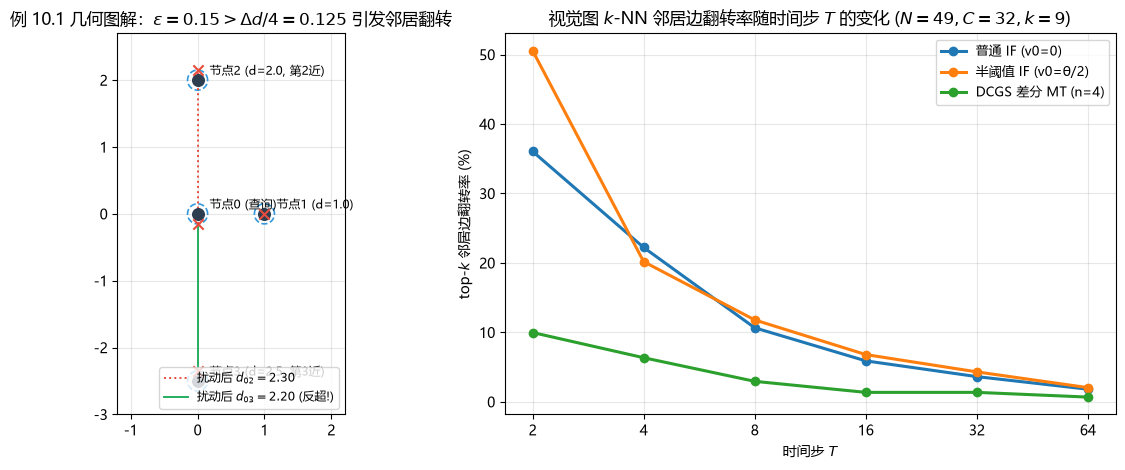

In [4]:
def if_encode_matrix(X, T, theta=1.0, v0_ratio=0.0, eps=1e-9):
    '''恒定非负特征矩阵 X (N, C) 经过 T 步 IF 编码后的平均突触后电位 phi(T)'''
    v = np.full_like(X, theta * v0_ratio, dtype=np.float64)
    s_sum = np.zeros_like(X, dtype=np.float64)
    for _ in range(T):
        v_pre = v + X
        s = (v_pre >= theta - eps).astype(np.float64)
        v = v_pre - theta * s
        s_sum += s
    return theta * (s_sum / T)

def dcgs_mt_encode_matrix(X, T, theta=1.0, n=4):
    '''DCGS 差分 MT 神经元向量化编码 (N, C)'''
    pos = np.array([theta / (2.0 ** (i - 1)) for i in range(1, n + 1)])
    lams = np.concatenate([pos, -pos])  # (2n,)
    lam_min = pos[-1]
    v = np.zeros_like(X, dtype=np.float64)
    m_r = np.zeros_like(X, dtype=np.float64)
    r_out = np.zeros_like(X, dtype=np.float64)
    for t in range(1, T + 1):
        x_in = X if t == 1 else 0.0
        m = v + m_r + x_in
        # 向量化最近阈值查找
        diffs = np.abs(m[..., None] - lams[None, None, :])
        idx = np.argmin(diffs, axis=-1)
        x_out = lams[idx]
        x_out = np.where(np.abs(m) < lam_min, 0.0, x_out)
        v = m - x_out
        m_r = m_r + (x_in - x_out) / t
        r_out = r_out + x_out / t
    return r_out

def compute_knn_sets_and_gaps(X, k=9):
    # 两两欧氏距离矩阵 (含自身，选邻居时排除自身)
    sq = np.sum(X ** 2, axis=1, keepdims=True)
    D2 = np.maximum(sq + sq.T - 2.0 * (X @ X.T), 0.0)
    D = np.sqrt(D2)
    N = X.shape[0]
    knn_sets = []
    gaps = np.zeros(N)
    for i in range(N):
        d_row = D[i].copy()
        d_row[i] = np.inf
        order = np.argsort(d_row)
        knn_sets.append(set(order[:k].tolist()))
        gaps[i] = d_row[order[k]] - d_row[order[k - 1]]  # d_(k+1) - d_(k)
    return knn_sets, gaps

# 生成 N=49, C=32 的非负簇状视觉特征（模拟 4 个语义区域，落入 [0, 1] 之间）
rng = np.random.default_rng(2026)
N, C, k = 49, 32, 9
centers = rng.uniform(0.25, 0.75, size=(4, C))
labels = rng.integers(0, 4, size=N)
X_vis = np.clip(centers[labels] + rng.normal(0.0, 0.14, size=(N, C)), 0.0, 0.99)
theta = 1.0

true_knn, true_gaps = compute_knn_sets_and_gaps(X_vis, k=k)
print(f"模拟视觉图 N={N}, C={C}, k={k}: 间隔 Delta d_k(i) 最小={true_gaps.min():.4f}, 中位={np.median(true_gaps):.4f}, 最大={true_gaps.max():.4f}")

T_list = [2, 4, 8, 16, 32, 64]
methods = [
    ("普通 IF (v0=0)", lambda T: if_encode_matrix(X_vis, T, theta=theta, v0_ratio=0.0)),
    ("半阈值 IF (v0=θ/2)", lambda T: if_encode_matrix(X_vis, T, theta=theta, v0_ratio=0.5)),
    ("DCGS 差分 MT (n=4)", lambda T: dcgs_mt_encode_matrix(X_vis, T, theta=theta, n=4)),
]

flip_rates = {name: [] for name, _ in methods}
max_l2_errs = {name: [] for name, _ in methods}

print("\n=== 脉冲近似误差与 k-NN 邻居翻转率实测 (N=49, C=32, k=9) ===")
for name, fn in methods:
    print(f"\n[{name}]")
    print(f"{'T':>3} | {'实测max_ε':>10} | {'理论ε_max':>10} | {'理论ε_RMS':>10} | {'边翻转率%':>9} | {'安全区翻转数':>10}")
    for T in T_list:
        X_hat = fn(T)
        node_l2 = np.linalg.norm(X_hat - X_vis, axis=1)
        eps_emp = float(np.max(node_l2))
        eps_rms_emp = float(np.sqrt(np.mean(node_l2 ** 2)))
        hat_knn, _ = compute_knn_sets_and_gaps(X_hat, k=k)

        changed_edges = sum(len(true_knn[i] - hat_knn[i]) for i in range(N))
        flip_pct = 100.0 * changed_edges / (N * k)
        # 检查所有满足 gap > 4 * eps_emp 的节点，翻转数必须严格为 0！
        safe_nodes = [i for i in range(N) if true_gaps[i] > 4.0 * eps_emp]
        safe_flips = sum(1 for i in safe_nodes if hat_knn[i] != true_knn[i])
        assert safe_flips == 0, f"安全区不应翻转！{name}, T={T}"

        if "v0=0" in name:
            eps_th_max = np.sqrt(C) * theta / T
            eps_th_rms = np.sqrt(C) * theta / (np.sqrt(3.0) * T)  # U[0, theta/T] 的 RMS = theta/(sqrt(3)*T)
        elif "v0=θ/2" in name:
            eps_th_max = np.sqrt(C) * theta / (2.0 * T)
            eps_th_rms = np.sqrt(C) * theta / (np.sqrt(12.0) * T)
            assert eps_emp <= eps_th_max + 1e-9
        else:
            eps_th_max = np.nan
            eps_th_rms = np.nan

        if "v0=0" in name:
            assert eps_emp <= eps_th_max + 1e-9

        flip_rates[name].append(flip_pct)
        max_l2_errs[name].append(eps_emp)
        th_max_s = f"{eps_th_max:10.4f}" if not np.isnan(eps_th_max) else f"{'—':>10}"
        th_rms_s = f"{eps_th_rms:10.4f}" if not np.isnan(eps_th_rms) else f"{'—':>10}"
        print(f"{T:3d} | {eps_emp:10.4f} | {th_max_s} | {th_rms_s} | {flip_pct:8.2f}% | {safe_flips:4d} / {len(safe_nodes):2d}")

print("\n全部断言通过：所有满足 Delta d_k(i) > 4*eps 的安全区节点均实现 0 翻转！")

# 绘制 2 联图: (a) 例 10.1 2D 几何翻转图; (b) 邻居翻转率随 T 衰减曲线
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.8))

# 左图: 例 10.1 几何示意 (eps = 0.15 翻转区)
eps_show = 0.15
X_flip = X_nodes + eps_show * delta_dirs
theta_ang = np.linspace(0, 2 * np.pi, 120)
for idx, (pt, label_s) in enumerate(zip(X_nodes, ['节点0 (查询)', '节点1 (d=1.0)', '节点2 (d=2.0, 第2近)', '节点3 (d=2.5, 第3近)'])):
    axes[0].scatter(pt[0], pt[1], s=70, color='#2c3e50', zorder=4)
    axes[0].plot(pt[0] + eps_show * np.cos(theta_ang), pt[1] + eps_show * np.sin(theta_ang),
                 color='#3498db', ls='--', lw=1.2)
    axes[0].scatter(X_flip[idx, 0], X_flip[idx, 1], s=55, marker='x', color='#e74c3c', zorder=5)
    axes[0].annotate(label_s, xy=(pt[0], pt[1]), xytext=(pt[0] + 0.18, pt[1] + 0.08), fontsize=8.5)
axes[0].plot([X_flip[0, 0], X_flip[2, 0]], [X_flip[0, 1], X_flip[2, 1]], color='#e74c3c', lw=1.4, ls=':', label='扰动后 $d_{02}=2.30$')
axes[0].plot([X_flip[0, 0], X_flip[3, 0]], [X_flip[0, 1], X_flip[3, 1]], color='#27ae60', lw=1.4, ls='-', label='扰动后 $d_{03}=2.20$ (反超!)')
axes[0].set_aspect('equal')
axes[0].set_xlim(-1.2, 2.2)
axes[0].set_ylim(-3.0, 2.7)
axes[0].set_title(r'例 10.1 几何图解：$\varepsilon=0.15 > \Delta d/4=0.125$ 引发邻居翻转')
axes[0].legend(loc='lower right', fontsize=8.5)
axes[0].grid(True, alpha=0.3)

# 右图: 翻转率 vs T
for name, _ in methods:
    axes[1].plot(T_list, flip_rates[name], marker='o', lw=2.2, label=name)
axes[1].set_xscale('log', base=2)
axes[1].set_xticks(T_list)
axes[1].set_xticklabels([str(t) for t in T_list])
axes[1].set_title('视觉图 $k$-NN 邻居边翻转率随时间步 $T$ 的变化 ($N=49, C=32, k=9$)')
axes[1].set_xlabel('时间步 $T$')
axes[1].set_ylabel('top-$k$ 邻居边翻转率 (%)')
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
